In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import sklearn
from sklearn.model_selection import train_test_split
from sklearn.utils import resample
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.ensemble import GradientBoostingClassifier

import joblib

import warnings
warnings.filterwarnings('ignore')

# EDA

In [2]:
df = pd.read_csv('DataSet.csv')
df

,Unnamed: 0,F1,F2,F3,F4,F5,F6,F7,F8,F9,...,F3915,F3916,F3917,F3918,F3919,F3920,F3921,F3922,F3923,F3924
0,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0,1,0,0,1,0,0,1,0,0
1,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0,1,0,0,1,0,1,0,0,0
2,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0,1,0,0,1,0,0,1,0,0
3,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0,1,0,0,1,0,0,1,0,0
4,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0,1,0,0,1,0,1,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9077,9078,0.5,NaN,0.5,0.5,NaN,0.5,NaN,NaN,NaN,...,0,1,0,0,1,1,0,0,0,1
9078,9079,1.0,NaN,1.0,1.0,NaN,1.0,NaN,NaN,NaN,...,0,1,0,0,1,0,1,0,0,1
9079,9080,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0,1,0,0,1,1,0,0,0,1
9080,9081,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0,1,0,0,1,0,0,1,0,1


In [3]:
req_cols = ['F115','F321','F527','F531','F670','F1692','F2082','F2122','F2582','F2678','F2737','F2956','F3043','F3836','F3887','F3889',
            'F3891','F3894','F3924']
df.drop(columns = [c for c in df.columns if c not in req_cols], inplace = True)
df.shape

(9082, 19)

In [4]:
df

,F115,F321,F527,F531,F670,F1692,F2082,F2122,F2582,F2678,F2737,F2956,F3043,F3836,F3887,F3889,F3891,F3894,F3924
0,0.53,1.09,1.32,1.12,1.0,1.0,0.0,0.009091,-0.08,NaN,-0.16,36.0,NaN,29814.53,170,G365D,selfemployed,30.0,0
1,0.30,1.19,0.77,0.76,0.0,0.0,0.0,0.000000,-0.25,-0.47,-0.05,99.0,NaN,371320.98,169,G365D,selfemployed,32.0,0
2,0.43,1.25,1.37,1.68,0.0,0.0,0.0,0.000000,-0.21,-0.46,0.00,100.0,NaN,546659.78,170,G365D,student,32.0,0
3,0.69,2.02,0.92,1.92,0.0,0.0,0.0,0.000000,0.09,-0.46,0.66,56.0,114.0,353339.72,170,G365D,selfemployed,45.0,0
4,0.53,0.78,1.23,0.74,0.0,0.0,0.0,0.000000,0.65,-0.42,-0.53,63.0,109.0,1116.11,171,G365D,student,30.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9077,0.67,0.94,0.89,1.75,0.0,4.0,0.0,0.142857,NaN,-0.34,-0.28,31.0,48.0,4996546.96,99,G365D,housewife,87.0,1
9078,0.52,1.13,0.77,1.35,0.0,1.0,0.0,0.005714,0.40,1.67,0.00,90.0,174.0,32410863.02,75,G365D,salaried,32.0,1
9079,1.00,1.00,1.00,1.00,0.0,0.0,0.0,0.000000,0.00,0.00,0.00,68.0,NaN,470522.18,135,G365D,selfemployed,34.0,1
9080,0.38,1.10,0.99,1.51,0.0,0.0,0.0,0.003597,0.02,-0.44,-0.33,106.0,277.0,50249.60,103,G365D,student,27.0,1


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9082 entries, 0 to 9081
Data columns (total 19 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   F115    8724 non-null   float64
 1   F321    8997 non-null   float64
 2   F527    8294 non-null   float64
 3   F531    8441 non-null   float64
 4   F670    9066 non-null   float64
 5   F1692   9075 non-null   float64
 6   F2082   9075 non-null   float64
 7   F2122   9078 non-null   float64
 8   F2582   5678 non-null   float64
 9   F2678   6508 non-null   float64
 10  F2737   8970 non-null   float64
 11  F2956   8057 non-null   float64
 12  F3043   3258 non-null   float64
 13  F3836   9082 non-null   float64
 14  F3887   9082 non-null   int64  
 15  F3889   9082 non-null   object 
 16  F3891   9082 non-null   object 
 17  F3894   9079 non-null   float64
 18  F3924   9082 non-null   int64  
dtypes: float64(15), int64(2), object(2)
memory usage: 1.3+ MB


In [6]:
df.isnull().sum()

F115      358
F321       85
F527      788
F531      641
F670       16
F1692       7
F2082       7
F2122       4
F2582    3404
F2678    2574
F2737     112
F2956    1025
F3043    5824
F3836       0
F3887       0
F3889       0
F3891       0
F3894       3
F3924       0
dtype: int64

In [7]:
df.drop(columns =['F3043'], inplace = True)

In [8]:
df.dropna(subset=['F115','F321','F670','F1692','F2082','F2122','F2737','F3894','F527','F531'], inplace = True)
df.shape

(7891, 18)

In [9]:
df.isnull().sum()

F115        0
F321        0
F527        0
F531        0
F670        0
F1692       0
F2082       0
F2122       0
F2582    2739
F2678    2066
F2737       0
F2956     672
F3836       0
F3887       0
F3889       0
F3891       0
F3894       0
F3924       0
dtype: int64

In [10]:
df.describe()

,F115,F321,F527,F531,F670,F1692,F2082,F2122,F2582,F2678,F2737,F2956,F3836,F3887,F3894,F3924
count,7891.000000,7891.000000,7891.000000,7891.000000,7891.000000,7891.000000,7891.000000,7891.000000,5152.000000,5.825000e+03,7891.000000,7219.000000,7.891000e+03,7891.000000,7891.000000,7891.000000
mean,0.565981,1.167234,1.008140,1.452147,0.093778,0.251299,0.018860,0.041423,0.074781,3.185973e+02,0.353418,137.099183,-4.992256e+07,106.262958,34.005956,0.010138
std,0.193060,0.405600,0.763693,0.911461,0.291538,0.772850,0.076513,0.128036,0.525851,2.139237e+04,21.887550,371.717452,6.056579e+08,91.705484,17.343326,0.100183
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-0.880000,-9.100000e-01,-0.940000,0.000000,-2.028284e+10,0.000000,-2.000000,0.000000
25%,0.440000,0.990000,0.840000,1.000000,0.000000,0.000000,0.000000,0.000000,-0.130000,-3.300000e-01,-0.390000,27.000000,5.150388e+04,33.000000,25.000000,0.000000
50%,0.510000,1.100000,1.000000,1.230000,0.000000,0.000000,0.000000,0.000000,0.000000,-1.200000e-01,-0.170000,66.000000,3.949863e+05,97.000000,33.000000,0.000000
75%,0.650000,1.310000,1.130000,1.700000,0.000000,0.000000,0.000000,0.010899,0.130000,3.000000e-02,0.000000,126.000000,2.122205e+06,151.000000,44.000000,0.000000
max,1.000000,10.600000,48.420000,20.960000,1.000000,14.000000,0.941667,1.000000,18.890000,1.626944e+06,1707.600000,11548.000000,1.615585e+10,1509.000000,94.000000,1.000000


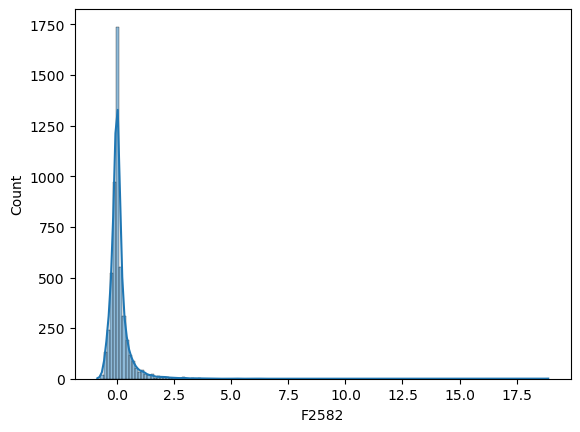

In [11]:
sns.histplot(df['F2582'], kde = True)
plt.show()

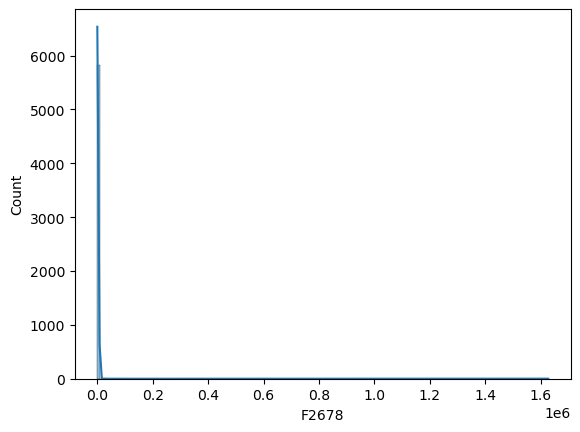

In [12]:
sns.histplot(df['F2678'], kde = True)
plt.show()

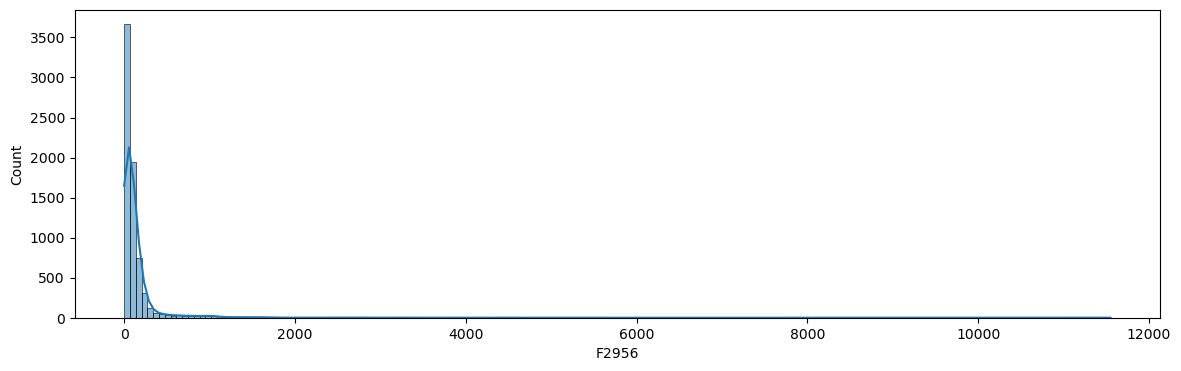

In [13]:
plt.figure(figsize = (14,4))
sns.histplot(df['F2956'], kde = True)
plt.show()

In [14]:
df['F2582'].fillna(df['F2582'].mean(), inplace = True)

In [15]:
df['F2678'].interpolate(method = 'quadratic', inplace = True)
df['F2678'].fillna(df['F2678'].median(), inplace = True)

In [16]:
df['F2956'].fillna(df['F2956'].median(), inplace = True)

In [17]:
df.duplicated().sum()

np.int64(0)

In [18]:
df['F3924'].value_counts()

F3924
0    7811
1      80
Name: count, dtype: int64

In [19]:
df['F3889'].nunique()

7

In [20]:
df['F3891'].nunique()

7

In [21]:
df['F3889'].unique()

array(['G365D', 'L365D', 'L180D', 'L90D', 'L31D', 'L14D', 'L7D'],
      dtype=object)

In [22]:
df['G365D'] = np.where(df['F3889'] == 'G365D', 1, 0)
df['L365D'] = np.where(df['F3889'] == 'L365D', 1, 0)
df['L180D'] = np.where(df['F3889'] == 'L180D', 1, 0)
df['L90D'] = np.where(df['F3889'] == 'L90D', 1, 0)
df['L31D'] = np.where(df['F3889'] == 'L31D', 1, 0)
df['L14D'] = np.where(df['F3889'] == 'L14D', 1, 0)
df['L7D'] = np.where(df['F3889'] == 'L7D', 1, 0)
df

,F115,F321,F527,F531,F670,F1692,F2082,F2122,F2582,F2678,...,F3891,F3894,F3924,G365D,L365D,L180D,L90D,L31D,L14D,L7D
0,0.53,1.09,1.32,1.12,1.0,1.0,0.0,0.009091,-0.080000,-0.12,...,selfemployed,30.0,0,1,0,0,0,0,0,0
1,0.30,1.19,0.77,0.76,0.0,0.0,0.0,0.000000,-0.250000,-0.47,...,selfemployed,32.0,0,1,0,0,0,0,0,0
2,0.43,1.25,1.37,1.68,0.0,0.0,0.0,0.000000,-0.210000,-0.46,...,student,32.0,0,1,0,0,0,0,0,0
3,0.69,2.02,0.92,1.92,0.0,0.0,0.0,0.000000,0.090000,-0.46,...,selfemployed,45.0,0,1,0,0,0,0,0,0
4,0.53,0.78,1.23,0.74,0.0,0.0,0.0,0.000000,0.650000,-0.42,...,student,30.0,0,1,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9077,0.67,0.94,0.89,1.75,0.0,4.0,0.0,0.142857,0.074781,-0.34,...,housewife,87.0,1,1,0,0,0,0,0,0
9078,0.52,1.13,0.77,1.35,0.0,1.0,0.0,0.005714,0.400000,1.67,...,salaried,32.0,1,1,0,0,0,0,0,0
9079,1.00,1.00,1.00,1.00,0.0,0.0,0.0,0.000000,0.000000,0.00,...,selfemployed,34.0,1,1,0,0,0,0,0,0
9080,0.38,1.10,0.99,1.51,0.0,0.0,0.0,0.003597,0.020000,-0.44,...,student,27.0,1,1,0,0,0,0,0,0


In [23]:
df['F3891'].unique()

array(['selfemployed', 'student', 'salaried', 'agriculture', 'housewife',
       'retired', 'others'], dtype=object)

In [24]:
df['selfemployed'] = np.where(df['F3891'] == 'selfemployed', 1, 0)
df['student'] = np.where(df['F3891'] == 'student', 1, 0)
df['salaried'] = np.where(df['F3891'] == 'salaried', 1, 0)
df['agriculture'] = np.where(df['F3891'] == 'agriculture', 1, 0)
df['housewife'] = np.where(df['F3891'] == 'housewife', 1, 0)
df['retired'] = np.where(df['F3891'] == 'retired', 1, 0)
df['others'] = np.where(df['F3891'] == 'others', 1, 0)

In [25]:
df.shape

(7891, 32)

In [26]:
df.drop(columns =['F3891','F3889'], inplace = True)

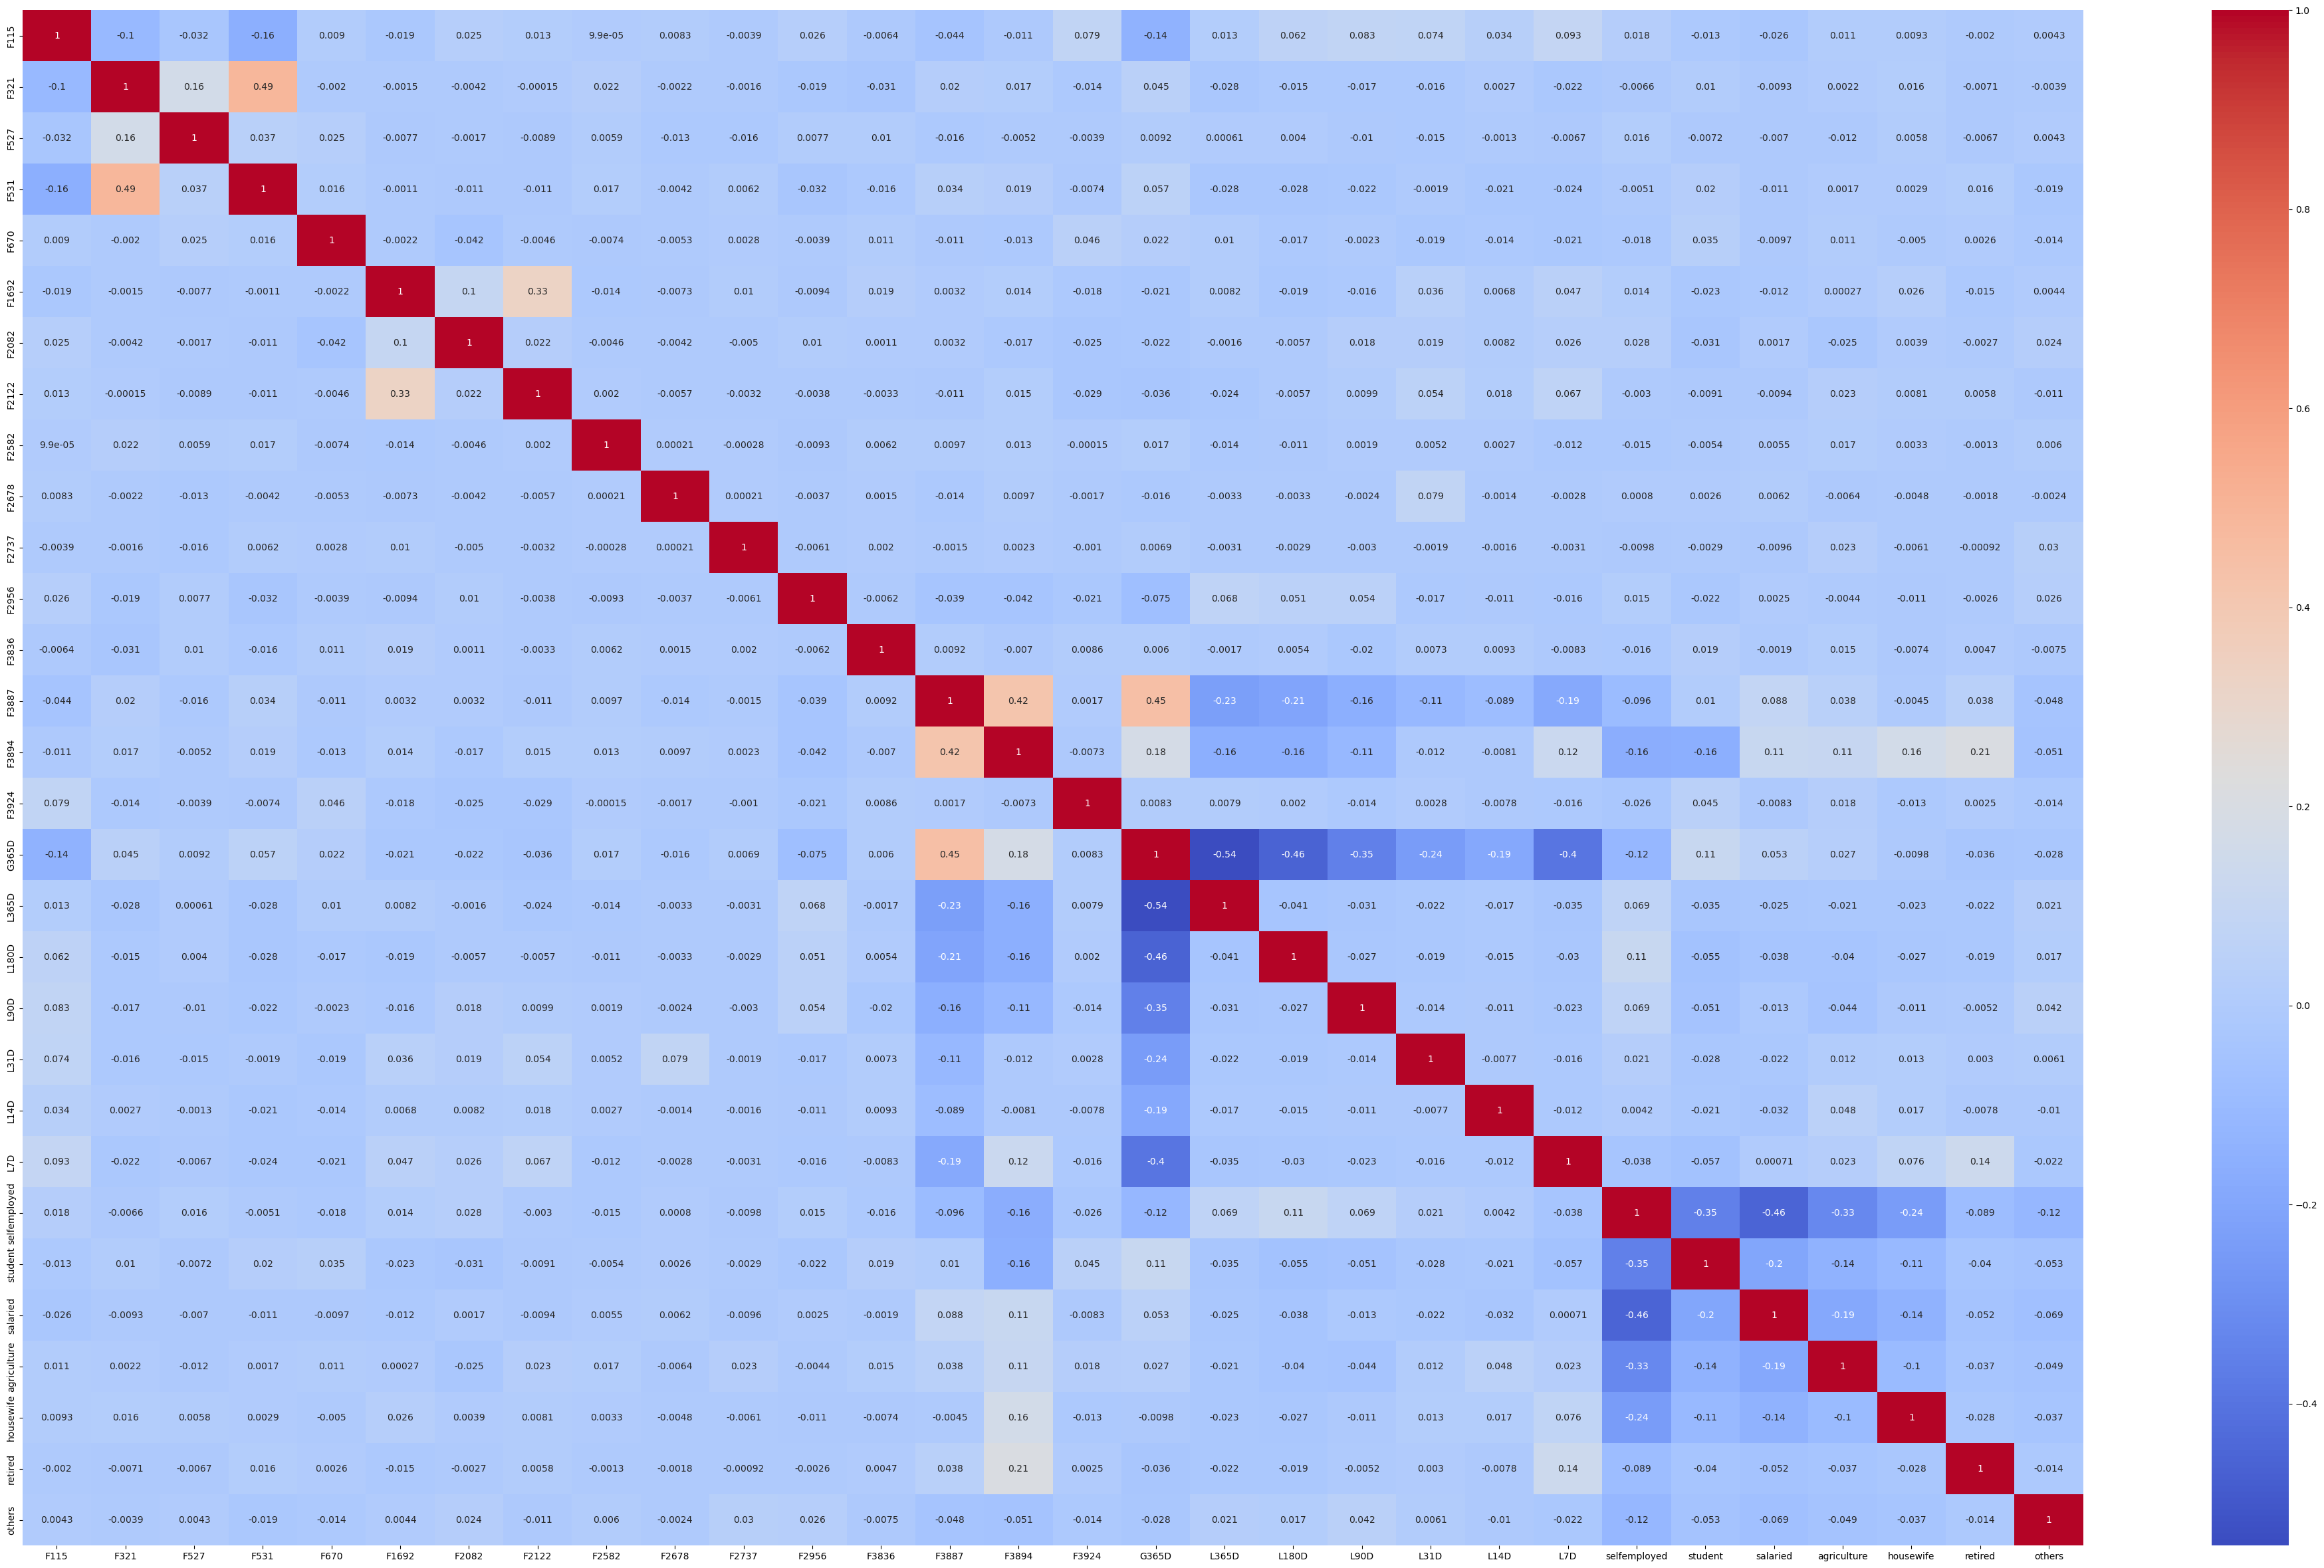

In [27]:
plt.figure(figsize = (50,30))
sns.heatmap(df.corr(), annot = True, cmap = 'coolwarm')
plt.show()

In [28]:
df.to_csv('Cleaned data.csv')

In [29]:
df_majority = df[df['F3924'] == 0]
df_minority = df[df['F3924'] == 1]

In [30]:
df_minority_upsampled = resample(df_minority, replace=True, n_samples=len(df_majority), random_state=42)
df = pd.concat([df_majority, df_minority_upsampled])

In [31]:
x = df.drop(['F3924'], axis=1)
y = df['F3924']

In [32]:
x

,F115,F321,F527,F531,F670,F1692,F2082,F2122,F2582,F2678,...,L31D,L14D,L7D,selfemployed,student,salaried,agriculture,housewife,retired,others
0,0.53,1.09,1.32,1.12,1.0,1.0,0.0,0.009091,-0.08,-0.120000,...,0,0,0,1,0,0,0,0,0,0
1,0.30,1.19,0.77,0.76,0.0,0.0,0.0,0.000000,-0.25,-0.470000,...,0,0,0,1,0,0,0,0,0,0
2,0.43,1.25,1.37,1.68,0.0,0.0,0.0,0.000000,-0.21,-0.460000,...,0,0,0,0,1,0,0,0,0,0
3,0.69,2.02,0.92,1.92,0.0,0.0,0.0,0.000000,0.09,-0.460000,...,0,0,0,1,0,0,0,0,0,0
4,0.53,0.78,1.23,0.74,0.0,0.0,0.0,0.000000,0.65,-0.420000,...,0,0,0,0,1,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9062,1.00,1.00,1.00,1.00,0.0,0.0,0.0,0.000000,0.00,0.064121,...,0,0,0,0,0,0,0,0,1,0
9072,0.43,1.39,1.11,1.73,0.0,0.0,0.0,0.000000,0.31,-0.210000,...,0,0,0,0,0,1,0,0,0,0
9035,1.00,1.39,0.99,1.35,0.0,0.0,0.0,0.033333,0.58,0.000000,...,0,0,0,1,0,0,0,0,0,0
9019,0.58,1.19,0.93,1.72,0.0,0.0,0.0,0.000000,-0.16,-0.330000,...,0,0,0,0,1,0,0,0,0,0


In [33]:
y

0       0
1       0
2       0
3       0
4       0
       ..
9062    1
9072    1
9035    1
9019    1
9059    1
Name: F3924, Length: 15622, dtype: int64

In [34]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.3, stratify=y, random_state=42)

In [35]:
model1 = GradientBoostingClassifier(
    n_estimators=100, 
    learning_rate=0.1, 
    max_depth=5, 
    random_state=42
)
model1.fit(x_train, y_train)

GradientBoostingClassifier(max_depth=5, random_state=42)

In [36]:
y_pred_train = model1.predict(x_train)
y_pred_test = model1.predict(x_test)

<Axes: >

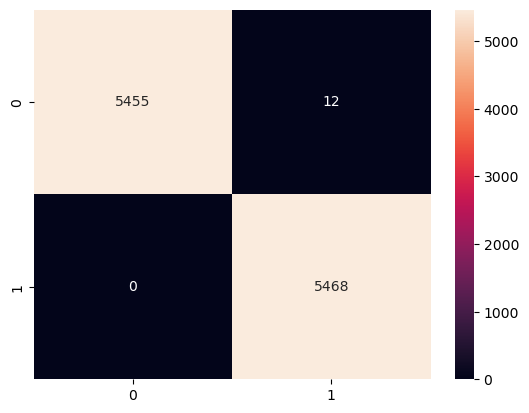

In [37]:
sns.heatmap(confusion_matrix(y_train, y_pred_train), annot=True, fmt='.4g')

In [38]:
accuracy_score(y_train, y_pred_train)

0.9989026063100137

In [39]:
print(classification_report(y_train, y_pred_train))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00      5467
           1       1.00      1.00      1.00      5468

    accuracy                           1.00     10935
   macro avg       1.00      1.00      1.00     10935
weighted avg       1.00      1.00      1.00     10935



<Axes: >

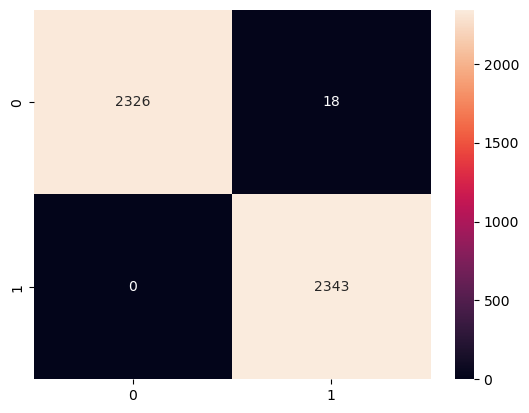

In [40]:
sns.heatmap(confusion_matrix(y_test, y_pred_test), annot=True, fmt='.4g')

In [41]:
accuracy_score(y_test, y_pred_test)

0.9961595903563046

In [42]:
print(classification_report(y_test, y_pred_test))

              precision    recall  f1-score   support

           0       1.00      0.99      1.00      2344
           1       0.99      1.00      1.00      2343

    accuracy                           1.00      4687
   macro avg       1.00      1.00      1.00      4687
weighted avg       1.00      1.00      1.00      4687



In [43]:
joblib.dump(model1, 'model5.pkl')

['model5.pkl']

In [45]:
model2 = ExtraTreesClassifier(n_estimators=100, random_state=42, n_jobs=-1)
model2.fit(x_train, y_train)

ExtraTreesClassifier(n_jobs=-1, random_state=42)

In [46]:
y_pred_train = model2.predict(x_train)
y_pred_test = model2.predict(x_test)

<Axes: >

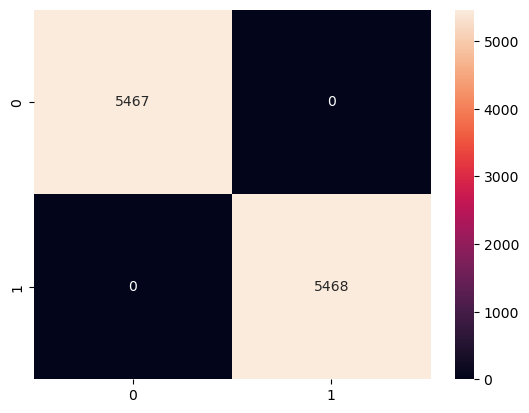

In [47]:
sns.heatmap(confusion_matrix(y_train, y_pred_train), annot=True, fmt='.4g')

In [48]:
accuracy_score(y_train, y_pred_train)

1.0

In [49]:
print(classification_report(y_train, y_pred_train))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00      5467
           1       1.00      1.00      1.00      5468

    accuracy                           1.00     10935
   macro avg       1.00      1.00      1.00     10935
weighted avg       1.00      1.00      1.00     10935



<Axes: >

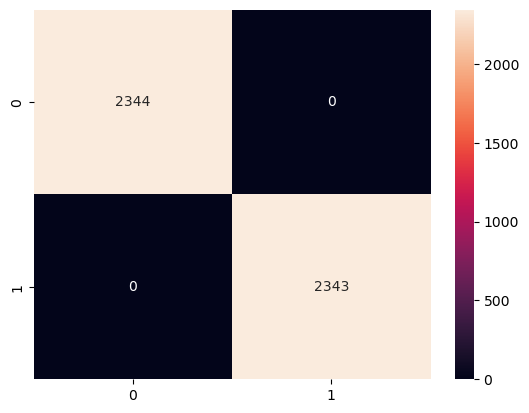

In [50]:
sns.heatmap(confusion_matrix(y_test, y_pred_test), annot=True, fmt='.4g')

In [51]:
accuracy_score(y_test, y_pred_test)

1.0

In [52]:
print(classification_report(y_test, y_pred_test))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00      2344
           1       1.00      1.00      1.00      2343

    accuracy                           1.00      4687
   macro avg       1.00      1.00      1.00      4687
weighted avg       1.00      1.00      1.00      4687



In [53]:
joblib.dump(model2, 'model6.pkl')

['model6.pkl']